# Лабораторная работа 3. Деревья решений. Часть 2

|  |  |
|---|---|
| Дисциплина | Машинное обучение |
| Студент | Масенькин Максим |
| Группа | ПИбд-41 |
| Вариант | 20 |

## Задание

С помощью библиотечной реализации дерева решений решить задачу из лабораторной работы
«Веб-сервис „Дерево решений“» по курсу «Методы искусственного интеллекта» на 99% своих данных.
Проверить работу модели на оставшемся проценте, сделать вывод.

| Пункт задания | Вариант 20 |
|---|---|
| Задача | зависимость суммы сделки от типа транзакции и месяца |
| Данные | сделки инсайдеров Tesla, 156 записей |
| Модель | дерево решений `DecisionTreeRegressor` |
| Разбиение | 99% на обучение, 1% на проверку |
| Образец кода | пособие «Теория и практика машинного обучения», пункт «Работа с деревьями решений», стр. 188–191, листинг 24 |

В курсе «Методы искусственного интеллекта» работа велась с набором сделок инсайдеров Tesla,
поэтому задача взята оттуда.

## Ход работы

1. Загрузить данные о сделках и выделить признаки задачи.
2. Обучить дерево на 99% сделок и проверить его на оставшихся.
3. Оценить качество модели кросс-валидацией и повторными разбиениями.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score
from sklearn.model_selection import KFold, ShuffleSplit, cross_val_predict, train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree

from mllab import RANDOM_STATE
from mllab.datasets import load_tesla
from mllab.preprocessing import calendar_features, log_target
from mllab.reporting import make_table


TRAIN_SIZE = 0.99
FOLDS = 10
REPEATS = 500

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10})
pd.set_option("display.width", 120)

## 1. Данные о сделках

Задача из ЛР 6 курса «Методы искусственного интеллекта» состоит в том, чтобы определить сумму
сделки инсайдера Tesla по типу транзакции и месяцу. Набор содержит 156 сделок с ноября 2021 по
декабрь 2022. Сумма сделки (`value`) — число, поэтому задача регрессионная и решается деревом
`DecisionTreeRegressor`.

При загрузке набор приведён к удобному виду:

- имена столбцов переведены в snake_case;
- числа с разделителями тысяч вида `"2,056,775"` преобразованы в целые;
- даты разобраны из строк.

Признаки задачи:

- `sale` — тип транзакции: 1 для продажи акций (`Sale`), 0 для исполнения опциона
  (`Option Exercise`), т. е. покупки акций по заранее оговорённой цене;
- `month` — номер месяца от 1 до 12 из даты сделки.

Ноябрь и декабрь есть в данных и за 2021, и за 2022 год — они получают одинаковые значения `month`.
Задача сформулирована через месяц, поэтому год не используется.

In [2]:
tesla = load_tesla()
X_tesla = pd.concat(
    [
        (tesla["transaction"] == "Sale").astype(int).rename("sale"),
        calendar_features(tesla["date"]),
    ],
    axis=1,
)
value = tesla["value"]
zero = value == 0
musk_sale = (tesla["insider"] == "Musk Elon") & (X_tesla["sale"] == 1)

make_table(
    {
        "сделок": len(tesla),
        "период": f"{tesla['date'].min():%d.%m.%Y} – {tesla['date'].max():%d.%m.%Y}",
        "продаж / исполнений опционов": f"{X_tesla['sale'].sum()} / {(1 - X_tesla['sale']).sum()}",
        "сделок с нулевой суммой": int(zero.sum()),
        "из них исполнений опционов": int((zero & (X_tesla["sale"] == 0)).sum()),
        "медианная сумма, $": f"{value.median():,.0f}",
        "максимальная сумма, $": f"{value.max():,.0f}",
    }
)

,значение
,
сделок,156
период,10.11.2021 – 28.12.2022
продаж / исполнений опционов,99 / 57
сделок с нулевой суммой,18
из них исполнений опционов,18
"медианная сумма, $","2,026,823"
"максимальная сумма, $","2,278,695,421"


Суммы лежат от нуля до 2.28 млрд \$, медиана 2.03 млн \$, самая крупная сделка больше медианной в
тысячу с лишним раз. Все 18 нулевых сделок — исполнения опционов. Ниже по месяцам показано, когда
они случались и когда продавал акции Илон Маск.

In [3]:
by_month = pd.DataFrame(
    {
        "продаж": X_tesla["sale"].groupby(X_tesla["month"]).sum(),
        "исполнений опционов": (1 - X_tesla["sale"]).groupby(X_tesla["month"]).sum(),
        "из них с нулевой суммой": zero.groupby(X_tesla["month"]).sum(),
        "продаж Маска": musk_sale.groupby(X_tesla["month"]).sum(),
    }
).rename_axis("месяц")
by_month.T

месяц,1,2,3,4,5,6,7,8,9,10,11,12
продаж,6,5,8,12,4,5,2,2,6,2,20,27
исполнений опционов,3,3,8,2,3,6,3,2,5,1,4,17
из них с нулевой суммой,0,0,6,0,0,3,0,0,3,0,0,6
продаж Маска,0,0,0,9,0,0,0,0,0,0,17,17


Нулевые сделки есть только в марте, июне, сентябре и декабре. По датам это 5-е число последнего
месяца квартала, и каждый раз их совершают одни и те же три руководителя. Скорее всего, это
ежеквартальное начисление акций в счёт вознаграждения, за которое ничего не платят. Получается,
что нулевую сумму тип сделки объясняет не полностью: из 57 исполнений опционов нулевых 18, и
отличить их можно только по месяцу.

Продажи Маска — самые крупные сделки набора, и все 43 пришлись на апрель, ноябрь и декабрь. Для
продаж месяц фактически показывает, продавал ли Маск.

Гистограмма ниже показывает, сколько сделок приходится на каждый интервал суммы. Столбцы продаж
и исполнений опционов поставлены друг на друга, поэтому высота столбца равна числу всех сделок в
интервале. Ось сумм логарифмическая: от 1 тыс. до 1 млрд \$ каждое деление в сто раз больше предыдущего. В обычной шкале
все сделки, кроме нескольких самых крупных, слились бы у нуля.

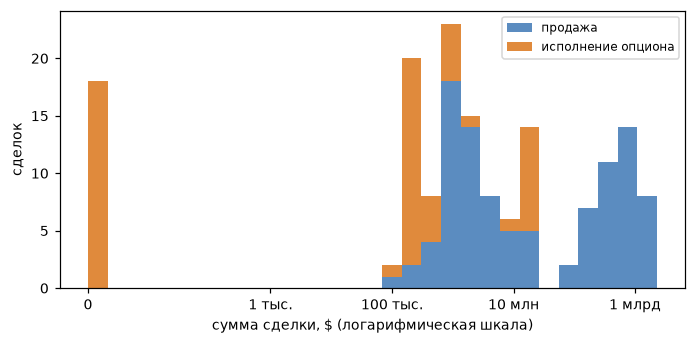

In [4]:
DOLLAR_TICKS = {0: "0", 1e3: "1 тыс.", 1e5: "100 тыс.", 1e7: "10 млн", 1e9: "1 млрд"}

fig, ax = plt.subplots(figsize=(6.4, 3.2))
bins = np.linspace(0, np.log1p(value.max()), 30)
ax.hist(
    [np.log1p(value[X_tesla["sale"] == 1]), np.log1p(value[X_tesla["sale"] == 0])],
    bins=bins,
    stacked=True,
    color=["#5b8cc0", "#e08a3c"],
    label=["продажа", "исполнение опциона"],
)
ax.set_xticks(np.log1p(list(DOLLAR_TICKS)), list(DOLLAR_TICKS.values()))
ax.set_xlabel("сумма сделки, $ (логарифмическая шкала)")
ax.set_ylabel("сделок")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Сделки распадаются на три группы: нулевые исполнения опционов, остальные сделки от 107 тыс. до
23 млн \$ и продажи Маска от 11.9 млн до 2.28 млрд \$.

## 2. Дерево решений

Дерево решений задаёт объекту последовательность вопросов вида «значение признака $x_j$ не
больше порога $b$?». Каждый вопрос делит сделки на две группы, и в каждой группе задаётся
следующий вопрос. Вершина, на которой вопросы заканчиваются, называется листом. В каждый лист
попадает часть сделок из обучающей выборки, и дерево регрессии предсказывает среднее значение
цели по ним.

Дерево строится сверху вниз, начиная с корня, в котором находятся все сделки. В каждой вершине
перебираются все признаки и все пороги. Пороги берутся посередине между соседними значениями
признака: у `sale` значения 0 и 1, поэтому порог один, 0.5, а у `month` значения от 1 до 12 и
порогов одиннадцать. Из всех вариантов выбирается вопрос, после которого группы получаются чище,
т. е. суммы внутри каждой из них ближе друг к другу. Дерево регрессии измеряет чистоту группы средним квадратом
отклонения цели от среднего по группе (`squared_error`):

$$D = \frac{1}{N} \sum_i (y_i - \bar{y})^2 .$$

Если у всех сделок группы одинаковое значение цели, $D = 0$, и чем сильнее значения разбросаны,
тем $D$ больше. В группе из двух сделок со значениями 12 и 16 среднее равно 14, и
$D = \frac{(12 - 14)^2 + (16 - 14)^2}{2} = 4$.

Деление оценивается тем, насколько оно уменьшило $D$. У двух новых групп $D$ свои, и их
усредняют с весами по размеру групп:

$$\Delta D = D - \frac{N_L}{N}\, D_L - \frac{N_R}{N}\, D_R ,$$

где $N$ — число сделок в вершине, $N_L$ и $N_R$ — в левой и правой группах. Веса нужны, чтобы
маленькая однородная группа не перевешивала большую. Выбрав деление с наибольшим $\Delta D$,
дерево повторяет то же самое в каждой из двух групп.

Важность признака показывает, насколько деления по этому признаку в сумме уменьшили разброс. Для
каждого деления его $\Delta D$ умножается на долю всех сделок, которая дошла до этой вершины, и
результаты складываются по признакам. Из-за этого множителя деление в корне весит больше, чем
деление маленькой группы внизу дерева. Если в обучающей выборке 154 сделки:

- деление корня с $\Delta D = 10$ добавляет к важности своего признака $1 \cdot 10 = 10$;
- деление группы из 14 сделок с тем же $\Delta D = 10$ добавляет только
  $\frac{14}{154} \cdot 10 \approx 0.9$.

В конце важности всех признаков делятся на их сумму, чтобы в сумме получилась 1. Эти значения
хранятся в поле `feature_importances_`.

Если обучать дерево на суммах в долларах, квадраты отклонений продаж Маска на сотни миллионов и
миллиарды долларов перевесят все остальные сделки, и дерево будет подстраиваться под них.
Поэтому цель логарифмируется:

$$y = \ln(1 + \text{сумма}) .$$

Единица добавлена из-за нулевых сумм, логарифм нуля не определён. Дерево обучается на
логарифмах, а прогноз переводится обратно в доллары.

В качестве ошибки прогноза возьмём модуль разности логарифмов факта $y_i$ и прогноза
$\hat{y}_i$, а в качестве средней ошибки по $n$ сделкам — среднее этих модулей (MAE, mean absolute
error):

$$\varepsilon_i = \lvert y_i - \hat{y}_i \rvert , \qquad
\mathrm{MAE} = \frac{1}{n} \sum_{i=1}^{n} \varepsilon_i .$$

Разность логарифмов равна логарифму отношения, поэтому ошибку $\varepsilon$ можно перевести в
разы: прогноз отличается от факта в $e^{\varepsilon}$ раз.

У признаков всего $2 \times 12 = 24$ сочетания значений, и в обучающей выборке встретились все.
С параметрами по умолчанию глубина не ограничена: дерево растёт, пока в каждом листе не останутся
сделки с одинаковой суммой или с одинаковыми значениями всех признаков, которых никаким порогом не
разделить. Поэтому каждый лист соответствует одному сочетанию «тип сделки и месяц», и прогноз
равен среднему логарифму суммы таких сделок в обучающей выборке. Разбиение по заданию: 154 сделки
в обучение, 2 в проверку.

In [5]:
X_train, X_test, value_train, value_test = train_test_split(
    X_tesla, value, train_size=TRAIN_SIZE, random_state=RANDOM_STATE
)
regressor = log_target(DecisionTreeRegressor(random_state=RANDOM_STATE)).fit(X_train, value_train)
tree = regressor.regressor_

make_table(
    {
        "обучающая выборка": len(X_train),
        "проверочная выборка": len(X_test),
        "глубина дерева": tree.get_depth(),
        "листьев": tree.get_n_leaves(),
        **{
            f"важность {name}": round(importance, 3)
            for name, importance in zip(X_tesla.columns, tree.feature_importances_, strict=True)
        },
    }
)

,значение
,
обучающая выборка,154
проверочная выборка,2
глубина дерева,8
листьев,24
важность sale,0.641
важность month,0.359


Дерево выросло до глубины 8 и 24 листьев. На диаграмме ниже представлены только первые три
уровня. В каждой вершине указаны вопрос, средний квадрат отклонения (`squared_error`), число
сделок (`samples`) и средний логарифм суммы (`value`). Чем насыщеннее цвет, тем больше среднее.

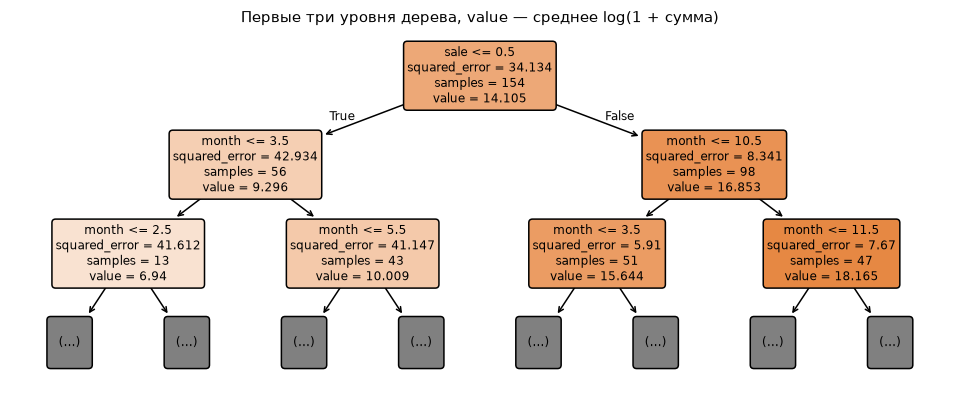

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.2))
plot_tree(
    tree,
    max_depth=2,
    feature_names=list(X_tesla.columns),
    filled=True,
    rounded=True,
    fontsize=8,
    ax=ax,
)
ax.set_title("Первые три уровня дерева, value — среднее log(1 + сумма)")
plt.show()

В корне 154 сделки, средний логарифм суммы 14.1 и $D = 34.1$. Лучшим первым делением оказался
вопрос `sale <= 0.5`, т. е. «исполнение опциона?»:

- исполнений опционов 56, средний логарифм 9.30, $D_L = 42.9$;
- продаж 98, средний логарифм 16.85, $D_R = 8.3$.

$$\Delta D = 34.1 - \frac{56}{154} \cdot 42.9 - \frac{98}{154} \cdot 8.3 = 13.2 .$$

Группа опционов вышла даже менее чистой, чем корень: в неё попали и нули, и суммы около
$e^{12}$–$e^{17}$. Зато продажи стали заметно однороднее, и в сумме разброс уменьшился. Тип сделки
отделяет продажи, но нулевые сделки им не отделить.

Дальше все деления идут по месяцу. В ветке опционов дерево отделяет месяцы с нулевыми сделками, в
ветке продаж — ноябрь и декабрь, когда продавал Маск. Важность месяца — 0.359, типа сделки — 0.641.

Ниже прогнозы для двух проверочных сделок.

In [7]:
def log_error(actual, predicted):
    return np.abs(np.log1p(actual) - np.log1p(predicted))


prediction = regressor.predict(X_test)
test_errors = log_error(value_test, prediction)
pd.DataFrame(
    {
        "инсайдер": tesla.loc[X_test.index, "insider"],
        "дата": tesla.loc[X_test.index, "date"].dt.date,
        "тип сделки": tesla.loc[X_test.index, "transaction"],
        "сумма, $": value_test,
        "прогноз, $": prediction.round().astype(int),
        "ошибка ε": test_errors.round(2),
        "во сколько раз": np.exp(test_errors).round(1),
    }
)

,инсайдер,дата,тип сделки,"сумма, $","прогноз, $",ошибка ε,во сколько раз
96,Baglino Andrew D,2022-02-28,Option Exercise,219520,536197,0.89,2.4
69,DENHOLM ROBYN M,2022-05-02,Sale,107447,6199319,4.06,57.7


Исполнение опциона Эндрю Баглино в феврале на 219 520 \$ дерево оценило в 536 197 \$, что в 2.4 раза больше истины.
Продажу Робин Денхолм в мае на 107 447 \$ оно оценило в 6.2 млн \$, ошибка в 58 раз. Это самая
маленькая продажа во всём наборе, а прогноз для неё равен среднему по другим майским продажам,
которые намного крупнее.
MAE на двух сделках 2.47, т. е. в среднем дерево ошиблось примерно в 12 раз.

Оценка качества по двум сделкам ненадёжна. MAE в этом случае усредняет всего две ошибки, и её
значение определяется прежде всего тем, какие сделки попали в проверку. При другом случайном
разбиении оценка могла бы оказаться совсем другой.

## 3. Оценка качества

Разбиение 99/1 повторено 500 раз со случайным выбором проверочных сделок, каждый раз дерево
обучалось заново и считалась MAE на двух проверочных сделках. Таблица ниже показывает, как
распределились эти 500 значений. Строка «у 25% разбиений меньше» содержит число, ниже которого
MAE оказалась у четверти разбиений, строка «у 50% разбиений меньше» — медиану. Столбец «во
сколько раз» переводит MAE в разы: $e^{\mathrm{MAE}}$.

In [8]:
splits = ShuffleSplit(n_splits=REPEATS, train_size=TRAIN_SIZE, random_state=RANDOM_STATE)
split_errors = []
for train, test in splits.split(X_tesla):
    model = log_target(DecisionTreeRegressor(random_state=RANDOM_STATE))
    model.fit(X_tesla.iloc[train], value.iloc[train])
    split_errors.append(log_error(value.iloc[test], model.predict(X_tesla.iloc[test])).mean())
split_errors = pd.Series(split_errors)

spread = pd.Series(
    {
        "разбиение по заданию": test_errors.mean(),
        "наименьшая": split_errors.min(),
        **{
            f"у {int(q * 100)}% разбиений меньше": split_errors.quantile(q)
            for q in (0.1, 0.25, 0.5, 0.75, 0.9)
        },
        "наибольшая": split_errors.max(),
    }
)
pd.DataFrame({"MAE": spread.round(2), "во сколько раз": np.exp(spread).round(1)})

,MAE,во сколько раз
разбиение по заданию,2.47,11.9
наименьшая,0.06,1.1
у 10% разбиений меньше,0.73,2.1
у 25% разбиений меньше,1.35,3.9
у 50% разбиений меньше,2.47,11.8
у 75% разбиений меньше,4.08,59.3
у 90% разбиений меньше,5.54,255.2
наибольшая,10.91,54574.6


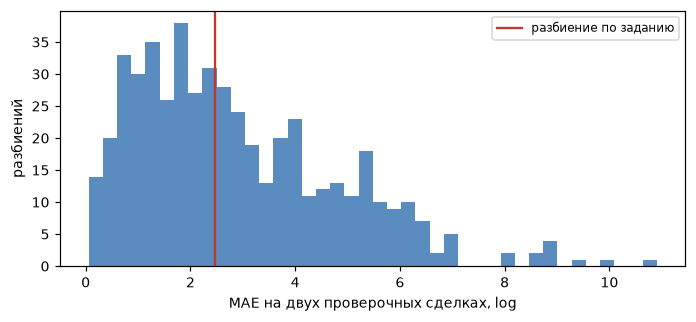

In [9]:
fig, ax = plt.subplots(figsize=(6.4, 3.0))
ax.hist(split_errors, bins=40, color="#5b8cc0")
ax.axvline(test_errors.mean(), color="#c0392b", linewidth=1.5, label="разбиение по заданию")
ax.set_xlabel("MAE на двух проверочных сделках, log")
ax.set_ylabel("разбиений")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

MAE на двух сделках зависит от того, какие сделки попали в проверку, сильнее, чем от модели. У
10% разбиений она меньше 0.73, т. е. ошибка примерно в 2 раза, у других 10% больше 5.54, в 255
раз. Разбиение по заданию случайно оказалось ровно на медиане, но с тем же успехом могло дать
0.06 или 10.91. Проверка на 1% данных показывает, как модель предсказала две конкретные сделки и
только.

Надёжнее кросс-валидация: выборка делится на 10 частей, модель 10 раз обучается на девяти частях
и проверяется на оставшейся. Каждая из 156 сделок ровно один раз попадает в проверку, и метрики
считаются по всем 156 прогнозам сразу.

Кроме MAE приводится коэффициент детерминации в логарифмической шкале:

$$R^2 = 1 - \frac{\sum_i (y_i - \hat{y}_i)^2}{\sum_i (y_i - \bar{y})^2} ,$$

где $\hat{y}_i$ — прогноз модели, $\bar{y}$ — среднее значение цели. В числителе стоит квадрат
ошибки модели, в знаменателе — квадрат ошибки константы, которая всегда предсказывает среднее.
При $R^2 = 0$ модель не лучше среднего, при $R^2 = 1$ попадает точно, отрицательный $R^2$ значит,
что модель хуже константы.

In [10]:
folds = KFold(FOLDS, shuffle=True, random_state=RANDOM_STATE)
predicted = cross_val_predict(
    log_target(DecisionTreeRegressor(random_state=RANDOM_STATE)), X_tesla, value, cv=folds
)
cv_mae = log_error(value, predicted).mean()

make_table(
    {
        "MAE": round(cv_mae, 2),
        "во сколько раз": round(np.exp(cv_mae), 1),
        "R²": f"{r2_score(np.log1p(value), np.log1p(predicted)):.2f}",
    },
    column=f"кросс-валидация, {FOLDS} частей",
)

,"кросс-валидация, 10 частей"
,
MAE,2.97
во сколько раз,19.5
R²,0.50


По кросс-валидации MAE дерева равна 2.97, т. е. в среднем прогноз отличается от факта примерно в
20 раз. $R^2 = 0.50$: дерево объясняет половину разброса логарифма суммы.

Тип сделки и месяц объясняют сумму сделки лишь частично. В задаче нет признаков, от которых она
зависит сильнее: инсайдера и числа акций.

## Выводы

1. Дерево регрессии, обученное на 99% сделок Tesla, ошиблось на двух проверочных сделках в 2.4 и
   58 раз.
2. По 500 повторным разбиениям MAE на двух сделках меняется от 0.06 до 10.91, поэтому проверка
   на 1% данных о качестве модели ничего не говорит.
3. Тип сделки отделяет продажи от исполнений опционов, остальное дерево делает по месяцу:
   нулевые сделки приходятся на последний месяц квартала, продажи Маска — на апрель, ноябрь и
   декабрь. Важность месяца — 0.359, типа сделки — 0.641.
4. На кросс-валидации MAE дерева равна 2.97, и оно объясняет половину разброса логарифма суммы
   ($R^2 = 0.50$). Тип транзакции и месяц определяют сумму сделки слабо.

## Контрольные вопросы

**1. Расскажите подробнее об используемой вами модели дерева решений.**

В scikit-learn реализован алгоритм CART. Дерево бинарное: в каждой вершине одно условие
$x_j \le b$ по одному признаку. `DecisionTreeRegressor` в каждой вершине перебирает все признаки
и пороги и выбирает деление, сильнее всего уменьшающее средний квадрат отклонения цели. Лист
возвращает среднее значение цели у попавших в него обучающих объектов. Средний квадрат
отклонения чувствителен к выбросам, поэтому дерево обучалось на логарифме суммы.

Без ограничений дерево растёт, пока листья не станут однородными, и легко переобучается. Рост
ограничивают параметры `max_depth` и `min_samples_leaf`. Масштабирования признаков дерево не
требует, т. к. сравнивает значения только с порогами, а его решения можно прочитать как набор
правил. Если у признаков мало значений, как здесь, дерево без ограничения глубины
превращается в таблицу средних по сочетаниям значений: 24 листа на 24 сочетания «тип и месяц».

**2. Какая типовая задача машинного обучения решается в обеих частях лабораторной?**

В обеих частях решается задача обучения с учителем: по объектам с известным ответом
восстановить зависимость ответа от признаков. В первой части предсказывается класс (выжил или
нет) — это классификация, а ответ на задание дают важности признаков обученного дерева. Во второй
части предсказывается сумма сделки — регрессия.

**3. Какими ещё моделями можно решить поставленные задачи?**

Для суммы сделки подходят линейная регрессия с месяцем в one-hot кодировке, гребневая регрессия,
метод k ближайших соседей и ансамбли деревьев: случайный лес и градиентный бустинг. С двумя
признаками любая из них сводится примерно к той же таблице средних по сочетаниям «тип и месяц».
Качество здесь ограничивают признаки: инсайдер и число акций дадут больше, чем смена модели.